# k-means by hand, and how many groups there are

Aurora, an online retailer, wants to split its 2,000 customers into groups
for a marketing campaign. Nobody has ever said which group a customer belongs
to: there is no $y$ anywhere in this notebook. All there is to work with is
the shape of the data, and the only question a clustering method answers is
*which customers look like they belong together?*

This notebook writes **k-means** by hand in a few lines, runs it on six
customers where every step can be checked on paper, then on all 2,000, and
then asks the question k-means leaves to you: *how many groups are there?*
The handout's section 2 tells the same story in prose.

## 1. Setup

In [1]:
# pip install numpy==1.26.4 pandas==2.1.1 matplotlib==3.8.0 scikit-learn==1.3.1

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score

from retail_data import make_customer_segments, TRUE_N_SEGMENTS, TRUE_SEGMENT_NAMES

FIGURES = Path.cwd().parent / "Figures"
FIGURES.mkdir(exist_ok=True)

BLUE, TEAL, RUST, GOLD, PLUM, INK = "#1F4E79", "#2E8B8B", "#B4483E", "#C9A227", "#7B4B94", "#1A1A1A"
PALETTE = [BLUE, TEAL, RUST, GOLD, PLUM]

customers = make_customer_segments()
X = customers[["annual_spend_eur", "visits_per_month"]].values
scaler = StandardScaler()
Xs = scaler.fit_transform(X)

print(f"{len(customers)} customers, 2 features, {TRUE_N_SEGMENTS} true segments "
      f"(kept aside: no method below sees them)")
customers.head()

2000 customers, 2 features, 4 true segments (kept aside: no method below sees them)


,annual_spend_eur,visits_per_month,true_segment
0,842.053353,5.911342,loyal high spenders
1,827.452084,5.062865,loyal high spenders
2,60.675247,1.189117,window shoppers
3,973.706252,0.100000,occasional big spenders
4,1082.809438,6.440865,loyal high spenders


## 2. Look at it first

This is what Aurora's marketing team has: two numbers per customer, annual
spend and visits per month, and no group name attached to either.

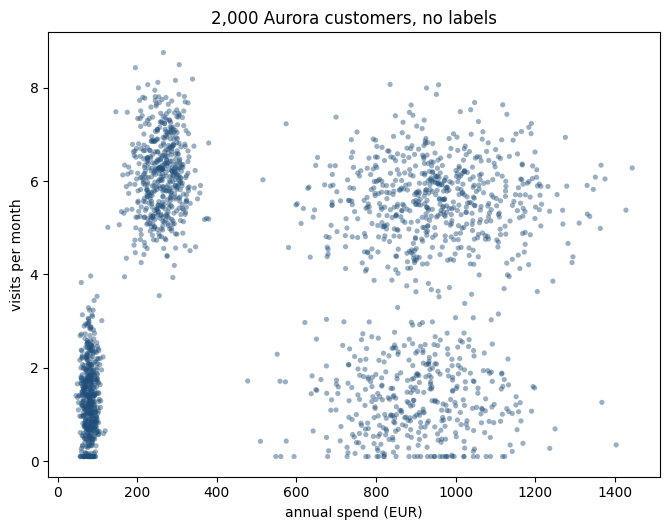

In [2]:
fig, ax = plt.subplots(figsize=(6.8, 5.4))
ax.scatter(X[:, 0], X[:, 1], s=14, color=BLUE, alpha=.45, edgecolor="none")
ax.set_xlabel("annual spend (EUR)")
ax.set_ylabel("visits per month")
ax.set_title("2,000 Aurora customers, no labels")
fig.tight_layout()
fig.savefig(FIGURES / "customers_unlabelled.png", dpi=150)
plt.show()

Four clouds are visible before any algorithm runs. That is the situation
k-means is built for: a few groups, each roughly round, each gathered around a
middle point. k-means describes every group by that middle point alone, its
**centre**, and gives each customer to the nearest one.

## 3. k-means by hand

The algorithm is two moves, repeated until nothing changes:

1. **Assign**: give every point to its nearest centre.
2. **Move**: put every centre at the mean of the points now assigned to it.

How good a grouping is gets measured by one number, the **within-cluster sum
of squares** (WCSS): for every point, the squared distance to its own centre,
added up over all points. Short lines from points to centres mean a small
WCSS. scikit-learn calls the same number `inertia_`.

Here are the two moves and the score, written out.

In [3]:
def assign(X, centres):
    """Index of the nearest centre, for every point."""
    squared_distances = ((X[:, None, :] - centres[None, :, :]) ** 2).sum(axis=2)
    return squared_distances.argmin(axis=1)


def move(X, labels, k):
    """Every centre to the mean of its points."""
    return np.array([X[labels == j].mean(axis=0) for j in range(k)])


def wcss(X, labels, centres):
    """Within-cluster sum of squares: squared distance of each point to its own centre, summed."""
    return ((X - centres[labels]) ** 2).sum()


def kmeans_by_hand(X, centres, max_rounds=100):
    """Repeat assign and move until the centres stop moving."""
    for round_ in range(1, max_rounds + 1):
        labels = assign(X, centres)
        new_centres = move(X, labels, len(centres))
        if np.allclose(new_centres, centres):
            break
        centres = new_centres
    return labels, centres, round_

### 3.1 Six customers, every step on paper

Six customers, with spend in hundreds of euros a year and visits per month, so
the two numbers are on comparable scales without any rescaling. Three are
small occasional buyers (A, B, C), three are big regular ones (D, E, F). Start
from a deliberately poor choice: both centres on customers of the *same*
group, A and B.

In [4]:
six = np.array([[1, 1], [1, 2], [2, 1],      # A, B, C
                [8, 6], [9, 6], [8, 7]],     # D, E, F
               dtype=float)
names = list("ABCDEF")
centres = six[[0, 1]].copy()                  # start on A and B

stages = []                                   # (title, labels, centres, wcss)
for round_ in (1, 2):
    labels = assign(six, centres)
    stages.append((f"round {round_}: assign", labels, centres.copy(), wcss(six, labels, centres)))
    centres = move(six, labels, 2)
    stages.append((f"round {round_}: move", labels, centres.copy(), wcss(six, labels, centres)))

for title, labels, c, w in stages:
    groups = ["".join(n for n, l in zip(names, labels) if l == j) for j in range(2)]
    print(f"{title:<17} groups {groups[0]:<4} {groups[1]:<4} centres {np.round(c, 3).tolist()}   WCSS = {w:.4f}")

centres6 = centres                            # where the six-customer run ended
labels_3 = assign(six, centres6)
print("round 3: assign gives the same groups:", np.array_equal(labels_3, stages[-1][1]))

round 1: assign   groups AC   BDEF centres [[1.0, 1.0], [1.0, 2.0]]   WCSS = 220.0000
round 1: move     groups AC   BDEF centres [[1.5, 1.0], [6.5, 5.25]]   WCSS = 56.2500
round 2: assign   groups ABC  DEF  centres [[1.5, 1.0], [6.5, 5.25]]   WCSS = 16.6875
round 2: move     groups ABC  DEF  centres [[1.333, 1.333], [8.333, 6.333]]   WCSS = 2.6667
round 3: assign gives the same groups: True


Read the WCSS column from top to bottom: 220, then 56.25, then 16.6875,
then 2.6667. Each move, and each re-assignment, can only shorten the lines or
leave them as they are, so the score never goes up; when a round changes
nothing, the algorithm stops. Here it stops at the obvious answer, ABC and
DEF, even though it started with both centres inside ABC.

The figure draws the four stages. Each dashed line joins a customer to its
centre; WCSS is the sum of the squared lengths of those lines.

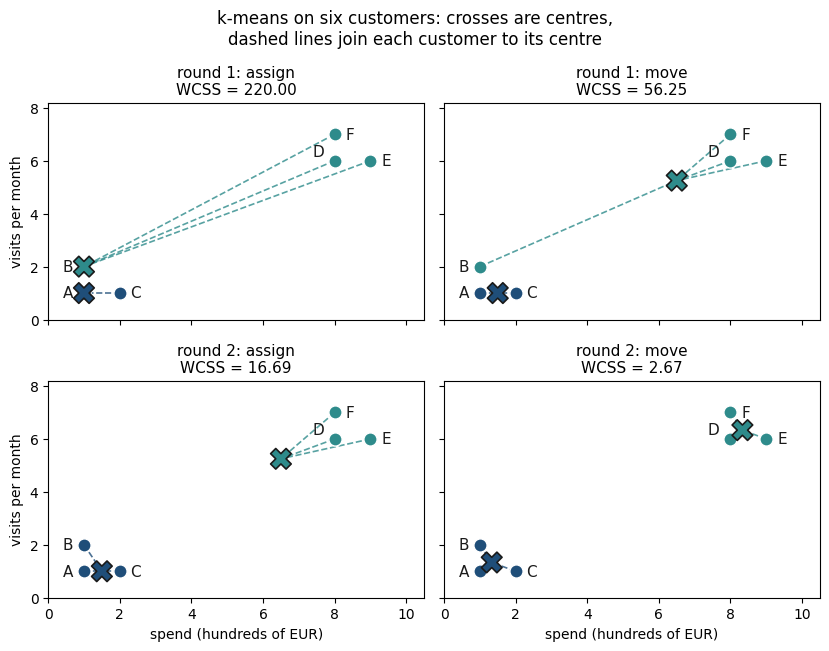

In [5]:
LABEL_AT = {"A": (-.3, 0, "right"), "B": (-.3, 0, "right"), "C": (.3, 0, "left"),
            "D": (-.3, .35, "right"), "E": (.3, 0, "left"), "F": (.3, 0, "left")}
fig, axes = plt.subplots(2, 2, figsize=(8.4, 6.6), sharex=True, sharey=True)
for ax, (title, labels, c, w) in zip(axes.ravel(), stages):
    for i, (x, l) in enumerate(zip(six, labels)):
        ax.plot([x[0], c[l, 0]], [x[1], c[l, 1]], "--", color=PALETTE[l], lw=1.2, alpha=.8)
        ax.scatter(*x, s=90, color=PALETTE[l], edgecolor="white", zorder=3)
        dx, dy, ha = LABEL_AT[names[i]]       # each letter placed where no centre lands on it
        ax.text(x[0] + dx, x[1] + dy, names[i], fontsize=11, color=INK, ha=ha, va="center")
    ax.scatter(c[:, 0], c[:, 1], marker="X", s=220, color=[PALETTE[0], PALETTE[1]],
               edgecolor=INK, linewidth=1.2, zorder=4)
    ax.set_title(f"{title}\nWCSS = {w:.2f}", fontsize=11)
    ax.set_xlim(0, 10.5); ax.set_ylim(0, 8.2)
for ax in axes[1]:
    ax.set_xlabel("spend (hundreds of EUR)")
for ax in axes[:, 0]:
    ax.set_ylabel("visits per month")
fig.suptitle("k-means on six customers: crosses are centres,\ndashed lines join each customer to its centre",
             fontsize=12)
fig.tight_layout()
fig.savefig(FIGURES / "kmeans_by_hand.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

### 3.2 All 2,000 customers, from two different starts

The same ten lines of code run on the real data, standardised first (lesson 2)
so that spend in euros does not drown visits per month. The start is four
customers picked at random. Run it from two different random picks, and draw
the path each centre travels.

In [6]:
def run_with_path(X, start, max_rounds=100):
    centres = start.copy()
    path = [centres.copy()]
    for _ in range(max_rounds):
        labels = assign(X, centres)
        new_centres = move(X, labels, len(centres))
        if np.allclose(new_centres, centres):
            break
        centres = new_centres
        path.append(centres.copy())
    labels = assign(X, centres)
    return labels, centres, np.array(path)

runs = {}
for seed in (1, 28):
    pick = np.random.default_rng(seed).choice(len(Xs), TRUE_N_SEGMENTS, replace=False)
    labels, centres, path = run_with_path(Xs, Xs[pick])
    runs[seed] = (labels, centres, path)
    print(f"start {seed:>2}: {len(path) - 1:>2} rounds of moves, final WCSS = {wcss(Xs, labels, centres):.1f}")

start  1:  7 rounds of moves, final WCSS = 374.1
start 28: 22 rounds of moves, final WCSS = 1390.4


Same data, same code, and two different answers. One start ends at a WCSS
of 374.1; the other stops at 1,390.4, more than three times worse, and stays
there, because from where it got stuck no single assign or move can lower the
score. k-means only guarantees it will stop, not that it will stop at the best
grouping.

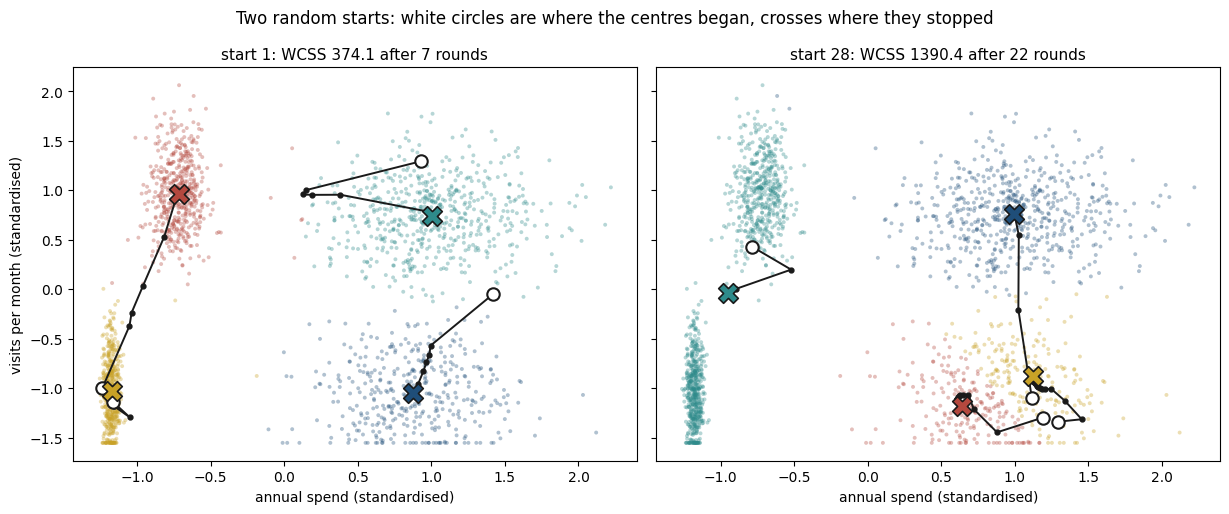

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12.4, 5.2), sharex=True, sharey=True)
for ax, seed in zip(axes, (1, 28)):
    labels, centres, path = runs[seed]
    for j in range(TRUE_N_SEGMENTS):
        ax.scatter(Xs[labels == j, 0], Xs[labels == j, 1], s=8, color=PALETTE[j], alpha=.35, edgecolor="none")
        ax.plot(path[:, j, 0], path[:, j, 1], "-o", color=INK, lw=1.4, markersize=3.5)
        ax.scatter(*path[0, j], marker="o", s=80, facecolor="white", edgecolor=INK, linewidth=1.5, zorder=4)
        ax.scatter(*path[-1, j], marker="X", s=200, color=PALETTE[j], edgecolor=INK, linewidth=1.2, zorder=5)
    ax.set_title(f"start {seed}: WCSS {wcss(Xs, labels, centres):.1f} after {len(path) - 1} rounds", fontsize=11)
    ax.set_xlabel("annual spend (standardised)")
axes[0].set_ylabel("visits per month (standardised)")
fig.suptitle("Two random starts: white circles are where the centres began, crosses where they stopped",
             fontsize=12)
fig.tight_layout()
fig.savefig(FIGURES / "kmeans_two_starts.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

On the right, two centres have ended up sharing one group while a single
centre covers two others. How often does that happen? Thirty random starts
answer it.

In [8]:
finals = []
for seed in range(30):
    pick = np.random.default_rng(seed).choice(len(Xs), TRUE_N_SEGMENTS, replace=False)
    labels, centres, _ = kmeans_by_hand(Xs, Xs[pick])
    finals.append(wcss(Xs, labels, centres))
finals = np.array(finals)
best = finals.min()
print(f"best WCSS over 30 starts: {best:.1f}, reached by {np.isclose(finals, best, atol=0.05).sum()} of 30")
print(f"worst WCSS over 30 starts: {finals.max():.1f}")

best WCSS over 30 starts: 374.1, reached by 29 of 30
worst WCSS over 30 starts: 1390.4


29 starts in 30 reach the best grouping; one does not. Rare, but a single
run gives no sign of being the unlucky one. The remedy is cheap: run k-means
several times from different starts and keep the run with the lowest WCSS.
scikit-learn's `KMeans` does exactly that with `n_init=10`, and it also picks
its starting centres more carefully than at random (a method called
k-means++, which prefers starting points far from those already chosen).

In [9]:
sk = KMeans(n_clusters=TRUE_N_SEGMENTS, n_init=10, random_state=0).fit(Xs)
print(f"scikit-learn KMeans, best of 10 starts: inertia_ = {sk.inertia_:.4f}")
print(f"by hand, best of 30 starts:             WCSS     = {best:.4f}")

scikit-learn KMeans, best of 10 starts: inertia_ = 374.0919
by hand, best of 30 starts:             WCSS     = 374.0919


The two agree to four decimal places: the ten lines above are k-means, and
scikit-learn adds the restarts and the better starting points.

## 4. How many groups?

k-means takes $k$, the number of groups, as an input. Nothing in the
algorithm says what it should be. Two diagnostics help, and they ask
different questions.

- **The elbow.** WCSS always falls as $k$ grows: with one group per customer
  it is exactly 0. So its value says nothing by itself. What helps is *where
  it stops falling steeply*: past the right number of groups, an extra centre
  only splits a group that was already fine, and buys little.
- **The silhouette.** For one point, take $a$, its average distance to the
  other points of its own group, and $b$, its average distance to the points
  of the nearest *other* group. Its silhouette is
  $s = (b - a) / \max(a, b)$: near 1 when the point sits well inside its own
  group, near 0 on a border, negative when it is closer to another group than
  to its own. The silhouette of a grouping is the average over all points.

First the silhouette of one point, on the six customers, where it can be
checked by hand.

In [10]:
labels6 = assign(six, centres6)                # the final ABC / DEF grouping
i = 1                                          # customer B
own = [j for j in range(6) if labels6[j] == labels6[i] and j != i]
other = [j for j in range(6) if labels6[j] != labels6[i]]
dist = lambda p, q: np.sqrt(((six[p] - six[q]) ** 2).sum())
a = np.mean([dist(i, j) for j in own])
b = np.mean([dist(i, j) for j in other])
s = (b - a) / max(a, b)
print("distances from B to its own group:  ", [round(dist(i, j), 3) for j in own], f"-> a = {a:.3f}")
print("distances from B to the other group:", [round(dist(i, j), 3) for j in other], f"-> b = {b:.3f}")
print(f"silhouette of B: (b - a) / max(a, b) = ({b:.3f} - {a:.3f}) / {max(a, b):.3f} = {s:.3f}")
print(f"mean silhouette of all six (scikit-learn): {silhouette_score(six, labels6):.3f}")

distances from B to its own group:   [1.0, 1.414] -> a = 1.207
distances from B to the other group: [8.062, 8.944, 8.602] -> b = 8.536
silhouette of B: (b - a) / max(a, b) = (8.536 - 1.207) / 8.536 = 0.859
mean silhouette of all six (scikit-learn): 0.868


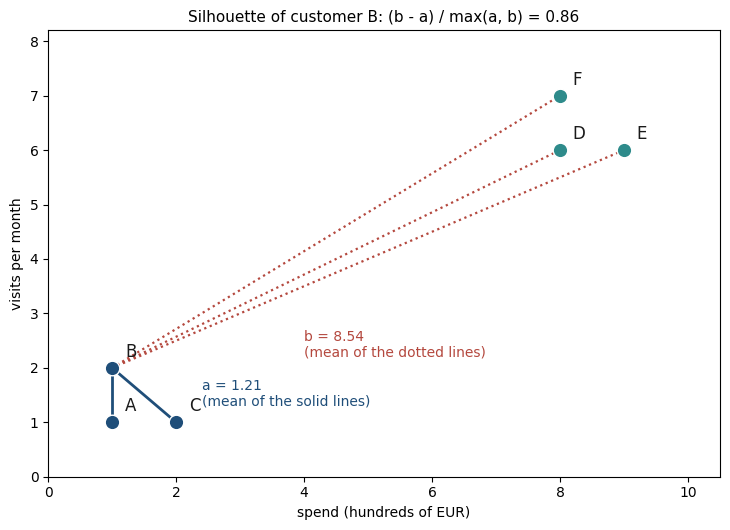

In [11]:
fig, ax = plt.subplots(figsize=(7.4, 5.4))
for j in own:
    ax.plot(*zip(six[i], six[j]), "-", color=BLUE, lw=2)
for j in other:
    ax.plot(*zip(six[i], six[j]), ":", color=RUST, lw=1.6)
for k_, (x, l) in enumerate(zip(six, labels6)):
    ax.scatter(*x, s=110, color=PALETTE[l], edgecolor="white", zorder=3)
    ax.text(x[0] + .2, x[1] + .2, names[k_], fontsize=12, color=INK)
ax.text(2.4, 1.3, f"a = {a:.2f}\n(mean of the solid lines)", color=BLUE, fontsize=10)
ax.text(4.0, 2.2, f"b = {b:.2f}\n(mean of the dotted lines)", color=RUST, fontsize=10)
ax.set_title(f"Silhouette of customer B: (b - a) / max(a, b) = {s:.2f}", fontsize=11)
ax.set_xlim(0, 10.5); ax.set_ylim(0, 8.2)
ax.set_xlabel("spend (hundreds of EUR)"); ax.set_ylabel("visits per month")
fig.tight_layout()
fig.savefig(FIGURES / "silhouette_one_point.png", dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

Now both diagnostics on the 2,000 customers, for $k$ from 1 to 8.

In [12]:
ks = range(1, 9)
wcss_curve, silhouette_curve = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Xs)
    wcss_curve.append(km.inertia_)
    silhouette_curve.append(silhouette_score(Xs, km.labels_) if k > 1 else np.nan)

curve_table = pd.DataFrame({"k": list(ks), "wcss": wcss_curve, "silhouette": silhouette_curve})
curve_table.round(3)

,k,wcss,silhouette
0,1,4000.000,NaN
1,2,2128.533,0.472
2,3,1125.763,0.564
3,4,374.092,0.690
4,5,320.605,0.593
5,6,286.486,0.525
6,7,244.460,0.528
7,8,210.368,0.474


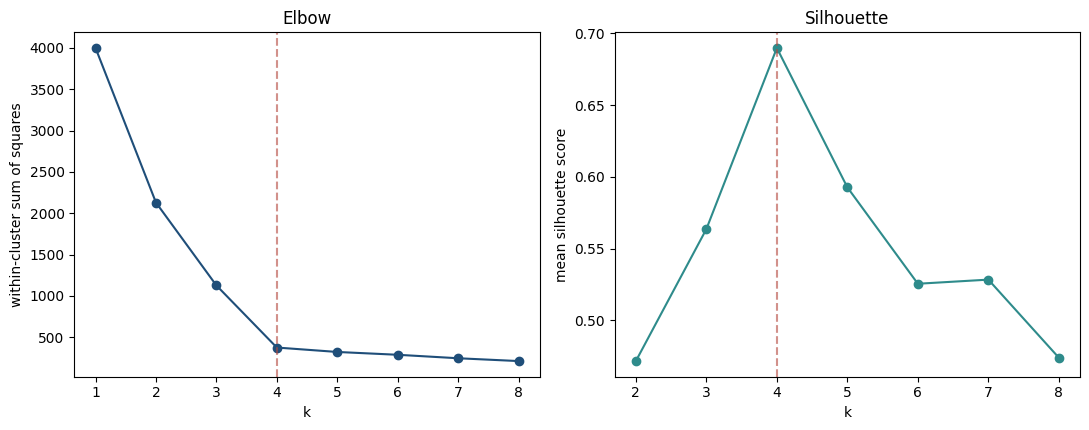

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.4))
ax1.plot(curve_table["k"], curve_table["wcss"], "o-", color=BLUE)
ax1.set_xlabel("k"); ax1.set_ylabel("within-cluster sum of squares")
ax1.set_title("Elbow")
ax1.axvline(TRUE_N_SEGMENTS, color=RUST, linestyle="--", alpha=.6)

ax2.plot(curve_table["k"][1:], curve_table["silhouette"][1:], "o-", color=TEAL)
ax2.set_xlabel("k"); ax2.set_ylabel("mean silhouette score")
ax2.set_title("Silhouette")
ax2.axvline(TRUE_N_SEGMENTS, color=RUST, linestyle="--", alpha=.6)

fig.tight_layout()
fig.savefig(FIGURES / "elbow_silhouette.png", dpi=150)
plt.show()

Both point to $k = 4$. The WCSS falls steeply up to 4 and slowly after it;
the silhouette is highest at 4 (0.690). Reading an elbow takes judgement, a
maximum does not, which is why the silhouette is the easier of the two to act
on. They agree here because the data really is four round, well separated
clouds; notebook 02 shows a case where looking at the silhouette alone
misleads.

## 5. The groups found, against the truth

This lesson knows something Aurora never would: which segment generated each
customer. That makes one more check possible. The **adjusted Rand index** (ARI)
compares two groupings of the same points. Take every pair of customers and
ask whether the two groupings agree about it: together in both, or apart in
both. The share of pairs on which they agree is the Rand index; the
"adjusted" version rescales it so that a random grouping scores 0 and an
identical one scores 1. It does not care what the groups are called: cluster
0 need not be "window shoppers".

In [14]:
final_km = KMeans(n_clusters=TRUE_N_SEGMENTS, n_init=10, random_state=0).fit(Xs)
ari = adjusted_rand_score(customers["true_segment"], final_km.labels_)
print(f"ARI against the true segments: {ari:.4f}")
pd.crosstab(customers["true_segment"], final_km.labels_,
            rownames=["true segment"], colnames=["k-means cluster"])

ARI against the true segments: 0.9850


k-means cluster,0,1,2,3
true segment,,,,
bargain hunters,1,0,499,0
loyal high spenders,0,1,5,594
occasional big spenders,1,397,0,2
window shoppers,499,0,1,0


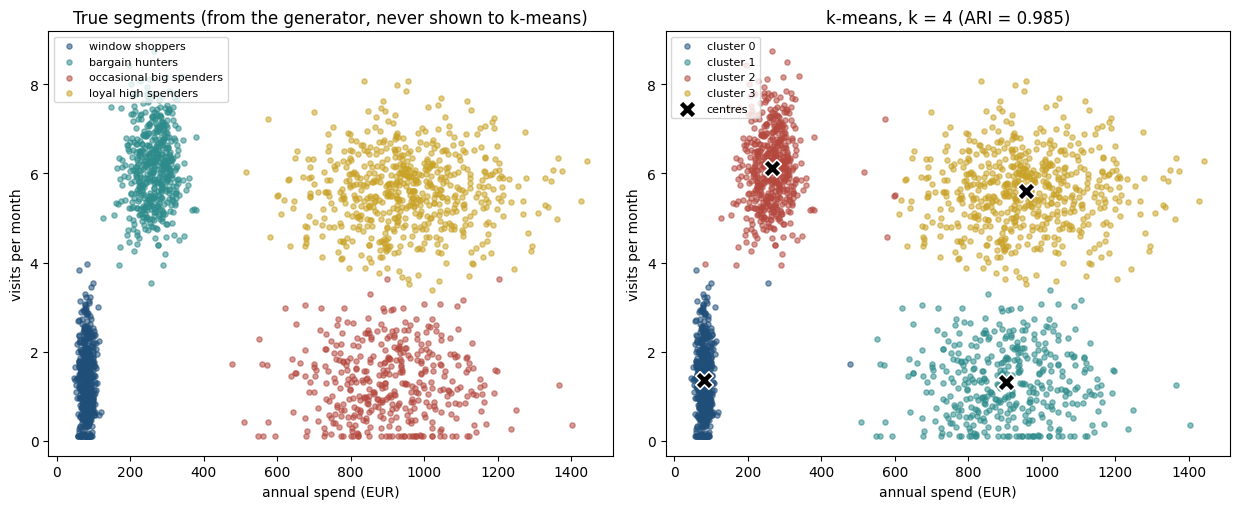

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 5.2))

for j, name in enumerate(TRUE_SEGMENT_NAMES):
    mask = customers["true_segment"] == name
    ax1.scatter(X[mask, 0], X[mask, 1], s=14, color=PALETTE[j], alpha=.55, label=name)
ax1.set_title("True segments (from the generator, never shown to k-means)")
ax1.set_xlabel("annual spend (EUR)"); ax1.set_ylabel("visits per month")
ax1.legend(fontsize=8, loc="upper left")

for j in range(TRUE_N_SEGMENTS):
    mask = final_km.labels_ == j
    ax2.scatter(X[mask, 0], X[mask, 1], s=14, color=PALETTE[j], alpha=.55, label=f"cluster {j}")
centres_original = scaler.inverse_transform(final_km.cluster_centers_)
ax2.scatter(centres_original[:, 0], centres_original[:, 1], marker="X", s=160,
            color="black", edgecolor="white", linewidth=1.2, zorder=5, label="centres")
ax2.set_title(f"k-means, k = 4 (ARI = {ari:.3f})")
ax2.set_xlabel("annual spend (EUR)"); ax2.set_ylabel("visits per month")
ax2.legend(fontsize=8, loc="upper left")

fig.tight_layout()
fig.savefig(FIGURES / "kmeans_vs_truth.png", dpi=150)
plt.show()

An ARI of 0.985: k-means has found the four segments almost exactly, and
the table shows where the few disagreements are. Remember that this check
exists only because the data is synthetic. Aurora's analysts would have the
right-hand panel and nothing to compare it with.

## 6. The predictable mistake

Having watched k-means recover these segments almost perfectly, most people
conclude that it is a reliable way to find groups in general. **The reasoning
is sound as far as it goes**: on data made of a few round clouds of similar
spread, k-means is fast and close to the best possible. What fails is the
assumption behind it. k-means describes every group by one centre and gives
each point to the nearest centre, so it can only ever produce round,
centre-shaped groups. Real data has no obligation to come in that shape.
Notebook 02 builds a dataset where it does not.

## Summary

- k-means repeats two moves: give each point to its nearest centre, move each
  centre to the mean of its points. Ten lines of NumPy, and on six customers
  every step can be checked by hand.
- Its score, the within-cluster sum of squares, can only go down or stay put,
  so the algorithm always stops, but not always at the best grouping: one
  random start in 30 stopped at 1,390.4 against the best 374.1. Several
  starts, keeping the best, is the remedy (`n_init=10` in scikit-learn).
- $k$ is your choice. The elbow of the WCSS curve and the maximum of the mean
  silhouette both point to 4 here.
- Against the true segments, which only synthetic data provides, k-means
  scores an adjusted Rand index of 0.985.